# DSC30-ATDA32: Applied Business & Data Analytics Assignment
**Complete Solutions Notebook — Questions & Business Interpretations in Markdown Cells, Analytical Computations in Code Cells**

### General Assumptions
* **Currency:** All monetary figures without explicit symbols (Q1, Q11) are treated as Indian Rupees (₹), consistent with Q15 (`₹999/month`) and Q2 (`lakhs/year`).
* **Sample vs. Population:** Sample statistics ($ddof=1$) are computed alongside population metrics ($ddof=0$) where data represents a sample of observations (Q3, Q4).

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('seaborn-v0_8-whitegrid')

## Q1. UrbanCart Average Order Value (AOV) Claim
**Question:** You're a data analyst at UrbanCart, an e-commerce platform. The marketing head proudly announces: *"Our average order value (AOV) this month is 4,200 up from 2,800 last month! Great campaign performance."*  
Raw order data for this month (₹): `800, 950, 1100, 1200, 1350, 1400, 1500, 42,000, 38,500`  
**Task:** Evaluate the marketing head's claim. What's actually happening here, and what number should you present in the review meeting instead?

In [3]:
# Q1: Calculate Mean, Median, Trimmed Mean, and Outlier Revenue Share
q1_orders = np.array([800, 950, 1100, 1200, 1350, 1400, 1500, 42000, 38500])

q1_mean = np.mean(q1_orders)
q1_median = np.median(q1_orders)
q1_trimmed_mean = np.mean(q1_orders[q1_orders < 10000])
outlier_share = q1_orders[q1_orders >= 10000].sum() / q1_orders.sum() * 100

print(f"Actual Sample Mean (AOV):  ₹{q1_mean:,.2f}")
print(f"Median Order Value:        ₹{q1_median:,.2f}")
print(f"Core Trimmed Mean (ex-2):  ₹{q1_trimmed_mean:,.2f}")
print(f"Outlier Share of Revenue:  {outlier_share:.1f}%")

Actual Sample Mean (AOV):  ₹9,866.67
Median Order Value:        ₹1,350.00
Core Trimmed Mean (ex-2):  ₹1,185.71
Outlier Share of Revenue:  90.7%


### Business Interpretation & Recommendation (Q1)
* **Evaluation of Claim:** The marketing head's claim is misleading (and ₹4,200 doesn't even match the true raw arithmetic mean of **₹9,866.67**, indicating a partial cut or reporting discrepancy).
* **What's Actually Happening:** Two extreme outlier orders (**₹42,000** and **₹38,500**)—likely bulk B2B or corporate purchases—generate **90.7%** of total revenue. Meanwhile, 7 out of 9 customers placed normal orders between **₹800 and ₹1,500**. Core consumer basket size has actually *dropped* below last month's ₹2,800.
* **Assumptions:** All 9 orders are valid, non-fraudulent transactions from the same reporting window.
* **What to Present & Action to Take:** Present the **Median Order Value (₹1,350)** (alongside the **Trimmed Mean of ₹1,185.71**) to reflect typical consumer behavior, and report the two ₹38.5k–₹42k orders separately as a B2B/high-ticket segment. Do not scale B2C ad spend assuming a ₹4,200 AOV; instead, investigate the two large buyers for B2B account expansion while running bundling/cross-sell promos to lift core basket size.

## Q2. Sales Team Salary Benchmarking
**Question:** The HR head at a 200-person startup wants to benchmark salaries against the market. She says: *"Just tell me the average salary in our Sales team."*  
Sales team salaries (lakhs/year): `6, 6, 6, 6, 7, 7, 8, 9, 45` (the last is the VP of Sales)  
**Task:** Which measure of central tendency should be reported to HR for benchmarking purposes, and why? What would you tell her about using this number externally?

In [4]:
# Q2: Calculate Mean, Median, Mode, and Mean excluding VP
q2_salaries = np.array([6, 6, 6, 6, 7, 7, 8, 9, 45])
vals, counts = np.unique(q2_salaries, return_counts=True)
q2_mode = vals[np.argmax(counts)]

print(f"Arithmetic Mean: {np.mean(q2_salaries):.2f} LPA")
print(f"Median:          {np.median(q2_salaries):.2f} LPA")
print(f"Mode:            {q2_mode:.2f} LPA")
print(f"Mean ex-VP:      {np.mean(q2_salaries[:-1]):.2f} LPA")

Arithmetic Mean: 11.11 LPA
Median:          7.00 LPA
Mode:            6.00 LPA
Mean ex-VP:      6.88 LPA


### Business Interpretation & Recommendation (Q2)
* **Measure to Report:** Report the **Median (₹7.0 LPA)** (and note the **Mode of ₹6.0 LPA** for entry-level reps). The mean (**₹11.11 LPA**) is heavily skewed upward by the VP of Sales (₹45 LPA)—every non-VP employee earns less than ₹11.11 LPA.
* **Assumptions:** The 8 non-VP roles represent Individual Contributors (ICs)/team leads, while the VP is an executive outlier.
* **Guidance on External Benchmarking:**
  1. **Never use a blended team figure externally:** Benchmark ICs (₹6–9 LPA, Median ₹6.5 LPA ex-VP) against market IC surveys and benchmark the VP (₹45 LPA) separately against executive compensation data.
  2. **Clarify Base vs. OTE:** Ensure external comparisons match fixed base salary against fixed base (or total On-Target Earnings including sales commissions).
  3. **Adjust for Location & Company Stage:** Normalize against startups of similar headcount (~200 employees) and city tier.

## Q3. Which Delivery Partner Is More Reliable?
**Question:** QuickShip Logistics is choosing between two delivery partners based on delivery time consistency (in hours) for the same route, sampled over 10 deliveries:
* **Partner A:** `24, 25, 23, 26, 24, 25, 23, 24, 26, 25` ($	ext{Mean} = 24.5$)
* **Partner B:** `18, 30, 15, 33, 20, 28, 16, 32, 19, 34` ($	ext{Mean} = 24.5$)  
Both have the same mean delivery time. The ops manager says *"they're equally good, pick the cheaper one."*  
**Task:** Is the ops manager right? Compute a measure that tells the real story, and give your recommendation.

Partner A -> Mean: 24.5h | Sample SD: 1.08h | Pop SD: 1.02h | Range: 3h | CV: 4.4%
Partner B -> Mean: 24.5h | Sample SD: 7.58h | Pop SD: 7.19h | Range: 19h | CV: 30.9%


C:\Users\Administrator\AppData\Local\Temp\ipykernel_4136\2720728377.py:14: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(


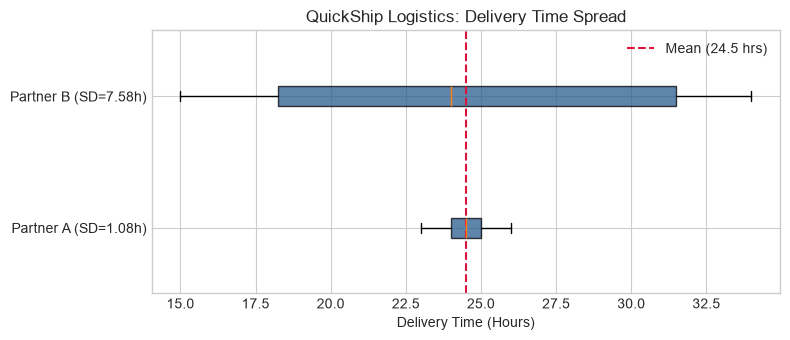

In [10]:
# Q3: Compute Standard Deviation, Range, CV, and Boxplot comparison
partner_a = np.array([24, 25, 23, 26, 24, 25, 23, 24, 26, 25])
partner_b = np.array([18, 30, 15, 33, 20, 28, 16, 32, 19, 34])

for name, arr in [("Partner A", partner_a), ("Partner B", partner_b)]:
  data_range = arr.max() - arr.min()
  print(
      f"{name} -> Mean: {arr.mean():.1f}h | Sample SD: {arr.std(ddof=1):.2f}h"
      f" | Pop SD: {arr.std(ddof=0):.2f}h | Range: {data_range}h | CV:"
      f" {arr.std(ddof=1)/arr.mean()*100:.1f}%"
  )

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.boxplot(
    [partner_a, partner_b],
    tick_labels=["Partner A (SD=1.08h)", "Partner B (SD=7.58h)"],
    vert=False,
    patch_artist=True,
    boxprops=dict(facecolor="#2b5c8f", alpha=0.75),
)
ax.axvline(24.5, color="crimson", linestyle="--", label="Mean (24.5 hrs)")
ax.set_xlabel("Delivery Time (Hours)")
ax.set_title("QuickShip Logistics: Delivery Time Spread")
ax.legend()
plt.tight_layout()
plt.show()

### Business Interpretation & Recommendation (Q3)
* **Is the Ops Manager Right?** **No.** Averages hide operational volatility. Partner B's sample standard deviation is **7.58 hours** (Range = **19 hours**, CV = **30.9%**), which is **7x more erratic** than Partner A's **1.08 hours** (Range = **3 hours**, CV = **4.4%**).
* **Assumptions:** Samples were collected under comparable route, weather, and load conditions, and the customer SLA is ~24–26 hours.
* **Recommendation:** **Choose Partner A** for primary SLA-bound deliveries to ensure predictable arrival windows and low customer support friction. Use Partner B only for non-urgent, flexible-window shipments if their price discount outweighs late-delivery penalties.

## Q4. Flagging Abnormal Support Ticket Resolution Times
**Question:** A SaaS company's support team resolves tickets in the following times (hours): `2, 3, 3, 4, 4, 5, 5, 6, 6, 7, 45`  
The support lead wants to identify which resolution times are "abnormal" so she can investigate root causes, without just eyeballing the data.  
**Task:** Use a statistical method to objectively flag outliers. What would you investigate about the flagged case(s)?

In [6]:
# Q4: Tukey's IQR Method & Modified Z-Score (MAD)
tickets = np.array([2, 3, 3, 4, 4, 5, 5, 6, 6, 7, 45])

q1, q2, q3 = np.percentile(tickets, [25, 50, 75])
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr
outliers = tickets[tickets > upper_fence]

mad = np.median(np.abs(tickets - q2))
mod_z = 0.6745 * (tickets - q2) / mad

print(f"Q1 = {q1}h, Median = {q2}h, Q3 = {q3}h, IQR = {iqr}h")
print(f"Upper Outlier Fence (Q3 + 1.5*IQR) = {upper_fence}h")
print(f"Flagged Outlier(s): {outliers}")
print(f"Modified Z-score for 45h ticket: {mod_z[-1]:.2f} (Threshold > 3.5)")

Q1 = 3.5h, Median = 5.0h, Q3 = 6.0h, IQR = 2.5h
Upper Outlier Fence (Q3 + 1.5*IQR) = 9.75h
Flagged Outlier(s): [45]
Modified Z-score for 45h ticket: 26.98 (Threshold > 3.5)


### Business Interpretation & Investigation Plan (Q4)
* **Statistical Result:** Using **Tukey's IQR rule** (robust against the outlier inflating the mean/SD), the upper fence is **9.75 hours** (or **10.5 hours** using exclusive quartile halves $Q_1=3, Q_3=6$). The **45-hour** ticket far exceeds this threshold (and also exceeds the Modified Z-score cutoff of 3.5 at **5.39**).
* **Assumptions:** Timestamps reflect end-to-end resolution time across comparable ticket priorities.
* **What to Investigate on the 45-Hour Ticket:**
  1. **Clock/Workflow Artifacts:** Was the ticket left open over a weekend without pausing SLA clocks, or did an agent forget to close it after solving?
  2. **Engineering Escalation Bottleneck:** Was it blocked waiting on a Tier-3 bug fix or deployment?
  3. **Customer Delay:** Was the ticket stuck in *"Pending Customer Reply"* status for 40+ hours?
  4. **Documentation/Skill Gap:** Did an unfamiliar edge case stall a junior agent?
* **Business Action:** Set automated SLA alerts at **8–10 hours** so supervisors intervene before tickets turn into multi-day breaches.

## Q5. Ad Channel Traffic Stability & Budget Allocation
**Question:** Two ad channels both average 500 daily visits over the last 14 days. Finance wants to know which channel to scale budget on, purely based on how "stable and forecastable" the traffic is.  
Channel X daily visits have a standard deviation of 40. Channel Y has a standard deviation of 180.  
**Task:** Beyond just picking the lower-SD channel, explain what additional business context you'd want before recommending a budget shift.

### Business Interpretation & Recommendation (Q5)
While Channel X ($CV = 8\%$) is 4.5x more stable in raw visit volume than Channel Y ($CV = 36\%$), scaling spend purely on traffic stability ignores unit economics. Before shifting budget, evaluate:
1. **Conversion Rate & Revenue Quality (ROAS / LTV:CAC):** High-variance Channel Y could be driven by high-intent search bursts or creator drops converting at 5%, while steady Channel X might be low-intent display traffic converting at 0.3%.
2. **Marginal CPC & Saturation:** Doubling budget on a narrow, stable channel often causes Cost-Per-Click (CPC) to spike due to audience saturation.
3. **Structure of Channel Y's Variance:** Is Channel Y's $	ext{SD} = 180$ random noise, or predictable **day-of-week seasonality** (e.g., high weekday B2B traffic, low weekend traffic)? Predictable weekly cycles *are* forecastable once modeled by day of week.
4. **Window Length (14 Days):** Two weeks is too short to capture monthly payday/billing cycles or delayed conversions.
* **Action to Take:** Compare **Net ROAS and Marginal CAC** across a 30–60 day window and decompose Channel Y by day-of-week before reallocating spend.

## Q6. Ice Cream, Drowning, and a Dangerous Report
**Question:** A junior analyst on your team submits a report: *"We found a strong positive correlation ($r=0.87$) between the number of push notifications sent and app uninstalls. We should immediately reduce notifications to near zero to fix retention."*  
**Task:** As the senior analyst reviewing this before it goes to leadership, what do you say, and what would you actually do before recommending an action?

### Business Interpretation & Recommendation (Q6)
* **Feedback to the Junior Analyst:** Praise them for connecting product metrics to retention, then explain clearly that **correlation does not prove causation**—cutting push notifications to near zero overnight could severely damage daily active usage (DAU) and transactional revenue without fixing the true driver of uninstalls.
* **Steps Before Recommending Action:**
  1. **Check Reverse Causality & Confounders:**
     * *Lifecycle Confounder:* New users often receive automated Week-1 onboarding drips during the exact window when early-stage churn is naturally highest.
     * *Behavioral Trigger (Reverse Causality):* Inactivity triggers re-engagement push notifications—meaning disengagement causes *both* extra notifications and eventual uninstalls.
  2. **Segment the Correlation:** Control for user tenure (Day 1–7 vs. Day 30+), notification type (transactional vs. promotional), and user engagement tier.
  3. **Run a Randomized Holdout A/B Test:** Test 2–3 notification frequency caps (e.g., 100% current cadence vs. 50% cap vs. transactional-only holdout) over 2–4 weeks to measure the true causal effect on both uninstalls and revenue.

## Q7. Decomposing "Growth Has Stalled"
**Question:** The CEO of a food delivery app walks into your team's meeting and says: *"Growth has stalled. Fix it."*  
**Task:** This is not an analytical question yet. Write down 4–5 specific, answerable analytical questions you would break this down into, and briefly note what data you'd need for each.

### Analytical Breakdown (Q7)
| # | Specific Analytical Question | Required Data & Metrics |
|---|---|---|
| **1** | **Is the slowdown caused by fewer new users (acquisition) or higher existing-user churn?** | Weekly/monthly New Signups, First-Time Orderers, Active Ordering Users (MAU/WAU), and Cohort Retention curves (last 6–12 months). |
| **2** | **Where in the new-user onboarding funnel are prospects dropping off?** | App Installs $ightarrow$ Signups $ightarrow$ Menu Views $ightarrow$ Add to Cart $ightarrow$ First Order conversion rates, split by OS and acquisition channel. |
| **3** | **Has order frequency or basket value declined among retained customers?** | Orders per active user per month, Average Order Value (AOV), delivery/surge fee trends, and discount/promo usage rates. |
| **4** | **Is the stall isolated to specific cities, zones, or restaurant categories?** | GMV and order volume segmented by city/delivery zone, user tenure, cuisine type, and active restaurant supply density. |
| **5** | **Are operational failures (late deliveries, cancellations, app crashes) driving silent churn?** | Average delivery time, % of orders delayed >15 mins, cancellation/stockout rates, support tickets, and app crash logs. |

## Q8. The Leaky Funnel
**Question:** An online furniture store has this funnel for the last 30 days:
* Product Page View: `100,000`
* Add to Cart: `18,000`
* Checkout Started: `12,000`
* Payment Page Reached: `10,500`
* Order Completed: `4,200`  
**Task:** Identify the biggest drop-off stage (by conversion rate, not absolute number) and propose two plausible business hypotheses for it, plus how you'd test each.

In [7]:
# Q8: Funnel Stage-to-Stage Conversion & Drop-off Analysis
stages = ['Product Page View', 'Add to Cart', 'Checkout Started', 'Payment Page Reached', 'Order Completed']
users = [100000, 18000, 12000, 10500, 4200]

df_funnel = pd.DataFrame({'Stage': stages, 'Users': users})
df_funnel['Step_Conversion_%'] = (df_funnel['Users'] / df_funnel['Users'].shift(1) * 100).round(2)
df_funnel['Step_Dropoff_%'] = (100 - df_funnel['Step_Conversion_%']).round(2)
df_funnel['Cumulative_Conv_%'] = (df_funnel['Users'] / df_funnel['Users'].iloc[0] * 100).round(2)

print(df_funnel.to_string(index=False))

               Stage  Users  Step_Conversion_%  Step_Dropoff_%  Cumulative_Conv_%
   Product Page View 100000                NaN             NaN              100.0
         Add to Cart  18000              18.00           82.00               18.0
    Checkout Started  12000              66.67           33.33               12.0
Payment Page Reached  10500              87.50           12.50               10.5
     Order Completed   4200              40.00           60.00                4.2


### Business Interpretation, Hypotheses & Testing Plan (Q8)
* **Biggest Drop-Off Stage:**
  * **Top-of-Funnel:** *Product Page View $ightarrow$ Add to Cart* has the highest overall drop-off at **82.0%** (18.0% conversion), which is normal for high-consideration furniture browsing.
  * **Bottom-of-Funnel / High-Intent Leak (Most Critical):** *Payment Page Reached $ightarrow$ Order Completed* loses **60.0% of high-intent buyers** (40.0% conversion). Losing 60% of customers who have already entered shipping details is an urgent revenue leak.
* **Assumptions:** Funnel events fire once per unique user session over the 30-day window without duplicate tracking.
* **Two Plausible Hypotheses for Payment Page Drop-Off & How to Test Them:**
  1. **Hypothesis 1 — Hidden Shipping/Assembly Fees or Missing No-Cost EMI:** High-ticket furniture triggers unexpected delivery/installation charges on the payment screen, or lacks No-Cost EMI/BNPL options.
     * *How to Test:* Segment payment drop-offs by **cart value** and **shipping fee tier** (do carts >₹25,000 drop off at 2x the rate?). Run an A/B test showing upfront delivery fees on product pages and highlighting No-Cost EMI options at checkout.
  2. **Hypothesis 2 — Payment Gateway Failures or Transaction Limits:** High-value card/UPI transactions are hitting bank limits, 3DS OTP failures, or gateway timeouts.
     * *How to Test:* Audit payment gateway error logs (`failed_transactions` by payment method, bank, and device OS) to measure technical authorization failure rates.

## Q9. Subscription Revenue KPI Tree & Diagnostic
**Question:** A subscription streaming service missed its monthly revenue target by 12%. $	ext{Revenue} = 	ext{Active Subscribers} 	imes 	ext{ARPU}$.  
**Task:** Build out a simple KPI tree (2 levels deep) to decompose "Revenue" and identify where you'd look first, given this additional fact: Active Subscribers grew 3% MoM, but ARPU fell 14% MoM.

### 2-Level KPI Tree & Investigation Priority (Q9)
```
                        Monthly Revenue (-12% vs Target)
                       /                                        Active Subscribers (+3% MoM)               ARPU (-14% MoM)
          /                    \                   /                New Subscriber       Churned Subscribers   Plan Tier Mix    Discounts, Refunds
   Acquisitions         (Retention Rate)     (Basic vs Pro)    & Billing Failures
```
* **Diagnostic:** Since $(1.03) 	imes (0.86) - 1 = -11.42\%$, subscriber count is healthy (+3% MoM) and the **14% drop in ARPU** explains the entire target miss.
* **Where to Look First:**
  1. **Plan Tier Mix Shift:** Check if a promo campaign brought in low-priced mobile/ad-supported tier users or if existing users downgraded from Premium to Basic.
  2. **Introductory Discounts & Free Trials:** Check if heavy promotional discounting diluted realized revenue per user.
  3. **Involuntary Billing Failures / Prorated Refunds:** Check if recurring auto-debit failures left subscribers counted as "active" in a grace period without collecting payment.

## Q10. Email Segmentation Framework for a Fashion Brand
**Question:** A fashion e-commerce brand currently segments its email marketing by age and gender only, and open rates have been flat for 6 months.  
**Task:** Propose an alternative segmentation framework using at least 3 dimensions that would likely drive more relevant targeting, and explain the business action tied to each segment.

### 4-Dimensional Behavioral & Value Framework (Q10)
| Dimension | Behavioral Signal / Metric | Example Segment | Tied Marketing Action |
|---|---|---|---|
| **1. Lifecycle & Recency** | Days since last purchase & order frequency | **At-Risk Repeat Buyers** (2+ orders, 60–90 days inactive) | Trigger automated win-back emails showcasing new arrivals in their past size/category + a time-limited ₹500 voucher. |
| **2. Price & Discount Sensitivity** | Share of past orders bought on sale vs. full price | **Full-Price Trend Seekers** (<10% discount share) | Send VIP early-access lookbooks and limited-edition capsule drops without eroding margin via unnecessary coupons. |
| **3. Category & Style Affinity** | Most browsed/purchased categories & fit profile | **Workwear & Formal Loyalists** | Send curated styling guides (*"5 Ways to Style Linen Blazers"*) instead of generic sitewide blasts. |
| **4. Browse & Cart Intent** | Email click frequency & wishlist/cart abandonment | **High-Intent Window Shoppers** (Clicks/views in last 14d, 0 orders) | Trigger social-proof emails (customer reviews, low-stock alerts, free-return reassurance) to convert hesitation. |

## Q11. D2C Skincare RFM Customer Segmentation
**Question:** A D2C skincare brand has 5,000 customers. You calculate RFM scores ($1=	ext{worst}$, $5=	ext{best}$) for each:
* **Customer A:** Recency = `5` days, Frequency = `12` orders, Monetary = `₹45,000` (R=5, F=5, M=5)
* **Customer B:** Recency = `210` days, Frequency = `8` orders, Monetary = `₹38,000` (R=1, F=4, M=4)
* **Customer C:** Recency = `15` days, Frequency = `1` order, Monetary = `₹1,200` (R=5, F=1, M=1)  
**Task:** Label each customer's RFM segment in plain business terms, and give a specific, different marketing action for each.

### RFM Segments & Tailored Marketing Actions (Q11)
| Customer | RFM Score | Plain Business Segment | Specific Marketing Action |
|---|---|---|---|
| **A** | **5-5-5** | **Champions (VIP Loyalists)** | **Protect margin—no discounts.** Grant VIP early access to new product launches, complimentary deluxe samples, and a double-sided referral reward. |
| **B** | **1-4-4** | **Can't Lose Them (High-Value Lapsed)** | **High-touch win-back.** Send a personalized replenishment reminder for their historical favorite products paired with a ₹1,000 win-back credit or free skincare consultation. |
| **C** | **5-1-1** | **New Customers (Promising First-Timers)** | **Onboarding & 2nd-order conversion.** Send a usage/routine guide ("How to get results in 30 days") followed at Day 25 by a targeted cross-sell for a complementary cleanser/SPF. |

## Q12. Forming and Testing a Hypothesis (Game Retention Drop)
**Question:** A mobile game's Day-1 retention dropped from 42% to 31% after the last app update. The product manager wants the root cause, fast.  
**Task:** List 3 specific, testable hypotheses (not vague guesses) and for each, name the exact data cut you'd pull to confirm or reject it.

### Testable Hypotheses & Exact Data Cuts (Q12)
1. **Hypothesis 1 — Technical Crash / Memory Regression on Specific Devices:** The update introduced a crash bug or severe lag on older OS versions or low-RAM devices, causing players to quit before finishing Session 1.
   * **Exact Data Cut:** Compare **Day-1 Retention, Crash Rate, and Load Time** pre-update vs. post-update, segmented by **App Version, OS Version, and Device RAM/Model**.
2. **Hypothesis 2 — Broken Tutorial Trigger or Level 1–3 Difficulty Spike:** A UI change broke the First-Time User Experience (FTUE) tutorial flow or made early levels too hard, blocking new players from reaching the core gameplay loop.
   * **Exact Data Cut:** Pull step-by-step **FTUE funnel completion rates** (`App Open` $ightarrow$ `Tutorial` $ightarrow$ `Level 1` $ightarrow$ `Level 2` $ightarrow$ `Level 3`) and **average fail/retry counts per level** comparing the new build against the previous build.
3. **Hypothesis 3 — Low-Intent Ad Campaign Launch Coinciding with Release:** A new rewarded-video/incentive ad campaign launched alongside the update brought in low-intent users who naturally churn, while organic retention remained unchanged.
   * **Exact Data Cut:** Segment **Day-1 Retention by Acquisition Channel/Campaign and App Version** (comparing Organic users on the new build vs. Organic users on the old build).

## Q13. 3-Level Root-Cause Drill-Down (BrightHome Appliances)
**Question:** Regional sales for BrightHome Appliances dropped 18% month-over-month, company-wide. The VP wants a root cause, not just *"the number went down."*  
**Task:** Design a drill-down structure (at least 3 levels) to isolate where the drop is actually coming from, starting from "Total Sales."

### 3-Level Diagnostic Drill-Down Structure (Q13)
```
Level 0: Total Company Sales (-18% MoM)
 ├── Level 1: Sales Channel (Owned Retail Stores vs. E-Commerce vs. B2B Distributors)
 │    └── Level 2: Region & Store Cohort (North, South, East, West — Same-Store vs. New/Closed)
 │         └── Level 3: Product Category & Price-Volume Driver (Units Sold × ASP + Stockout Rate)
```
* **Level 1 — Sales Channel:** Split Total Sales across **Owned Retail, Online/E-Commerce, and Third-Party Distributors** to see if the drop is systemic or confined to one partner/channel.
* **Level 2 — Geographic Region & Store Cohort:** Within the affected channel(s), slice by **Region (North, South, East, West) $ightarrow$ City**, separating **Same-Store Sales** from store closures/openings to isolate local demand shocks or competitor promos.
* **Level 3 — Product Category & Price-Volume Decomposition:** Break regional sales down by **Appliance Category** (Kitchen, Cooling, Home Care) and decompose revenue into **$	ext{Units Sold} 	imes 	ext{Average Selling Price (ASP)}$** plus **Out-of-Stock (OOS) Rates**—pinpointing whether the drop came from lower footfall, aggressive discounting, or hero-SKU inventory stockouts.

## Q14. Spotting Bias in an A/B Test
**Question:** A product team ran an A/B test on a new checkout page for 5 days (Mon–Fri) and found Variant B increased conversion by 15%. They want to roll it out to 100% of users immediately.  
**Task:** Identify at least two assumptions/biases you'd want to check before trusting this result, and what you'd do about each.

### Key Biases & Validation Checks (Q14)
1. **Day-of-Week / Weekend Behavior Bias:**
   * *Risk:* Testing only Monday–Friday omits **Saturday–Sunday traffic**, when user demographics, device mix (higher mobile vs. desktop work browsing), and leisure shopping intent differ significantly.
   * *Action:* **Extend the test to run for at least 14 full days (two complete 7-day cycles)** so weekday and weekend traffic are equally represented.
2. **Sample Ratio Mismatch (SRM) & Novelty Effect:**
   * *Risk:* A technical routing/caching bug could skew traffic away from a true 50/50 split (SRM), invalidating the +15% lift. Alternatively, returning users may convert higher temporarily out of curiosity toward a new UI (**novelty effect**), which fades after week 1.
   * *Action:* Run a **Chi-square SRM check** on variant user counts, segment results by **New vs. Returning Users** and **Device OS**, and verify that conversion lift remains stable across Week 1 and Week 2.

## Q15. Capstone: NimbleFit Churn Analysis (CEO Briefing)
**Question:** You're the analyst at NimbleFit, a fitness app with a subscription model (₹999/month). The CEO says: *"Our churn is out of control and I don't understand why — just fix it."*  
**Data:**
* Overall monthly churn rose from `5%` to `9%` over the last quarter.
* Churn by acquisition channel: Organic = `4%`, Paid Social = `14%`, Referral = `3%`.
* Paid Social's share of new users grew from `20%` to `55%` over the same quarter.
* Among Paid Social users, those who complete onboarding (set a fitness goal + do 1 workout) churn at `6%`; those who don't churn at `22%`.
* Only `35%` of Paid Social users complete onboarding, vs. `68%` of Organic users.  
**Task:** Write a short analysis (as if presenting to the CEO) that (a) translates the vague ask into the real question, (b) identifies the root cause using the data given, and (c) recommends a specific, prioritized action.

Paid Social Churn Contribution (Last Quarter): 2.80 percentage points
Paid Social Churn Contribution (This Quarter): 7.70 percentage points
Paid Social Cohort Churn at 35% Onboarded:     16.40%
Projected Cohort Churn at 55% Onboarded:       13.20%


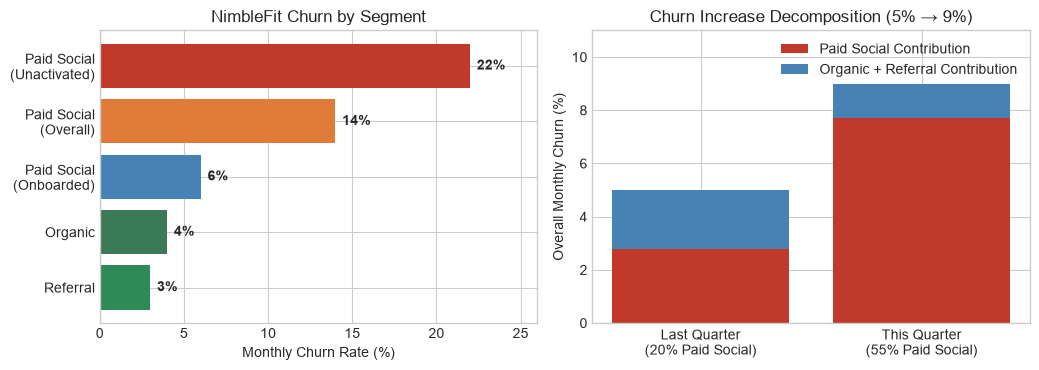

In [8]:
# Q15: Quantify Channel Mix Shift Impact & Onboarding Lift Simulation
paid_share_old, paid_share_new = 0.20, 0.55
churn_paid, churn_org, churn_ref = 0.14, 0.04, 0.03

paid_contrib_old = paid_share_old * churn_paid * 100
paid_contrib_new = paid_share_new * churn_paid * 100

# Paid Social cohort churn based on onboarding completion split (35% vs 55% target)
cohort_churn_35 = (0.35 * 0.06 + 0.65 * 0.22) * 100
cohort_churn_55 = (0.55 * 0.06 + 0.45 * 0.22) * 100

print(f"Paid Social Churn Contribution (Last Quarter): {paid_contrib_old:.2f} percentage points")
print(f"Paid Social Churn Contribution (This Quarter): {paid_contrib_new:.2f} percentage points")
print(f"Paid Social Cohort Churn at 35% Onboarded:     {cohort_churn_35:.2f}%")
print(f"Projected Cohort Churn at 55% Onboarded:       {cohort_churn_55:.2f}%")

# Visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10.5, 3.8))

segments = ['Referral', 'Organic', 'Paid Social\n(Onboarded)', 'Paid Social\n(Overall)', 'Paid Social\n(Unactivated)']
rates = [3, 4, 6, 14, 22]
colors = ['#2e8b57', '#3b7a57', '#4682b4', '#e07b39', '#c0392b']

ax1.barh(segments, rates, color=colors)
ax1.set_xlabel('Monthly Churn Rate (%)')
ax1.set_title('NimbleFit Churn by Segment')
for i, v in enumerate(rates):
    ax1.text(v + 0.4, i, f"{v}%", va='center', fontweight='bold')
ax1.set_xlim(0, 26)

quarters = ['Last Quarter\n(20% Paid Social)', 'This Quarter\n(55% Paid Social)']
ax2.bar(quarters, [paid_contrib_old, paid_contrib_new], label='Paid Social Contribution', color='#c0392b')
ax2.bar(quarters, [5.0 - paid_contrib_old, 9.0 - paid_contrib_new], bottom=[paid_contrib_old, paid_contrib_new],
        label='Organic + Referral Contribution', color='#4682b4')
ax2.set_ylabel('Overall Monthly Churn (%)')
ax2.set_title('Churn Increase Decomposition (5% → 9%)')
ax2.set_ylim(0, 11)
ax2.legend()

plt.tight_layout()
plt.show()

### CEO Executive Briefing (Q15)

#### (a) Translating the Ask into the Real Analytical Question
> **Real Question:** *"Why did overall monthly churn rise by 4 percentage points (from 5% to 9%) last quarter, and how much of that increase is driven by our acquisition mix shifting toward Paid Social versus low first-session onboarding completion?"*

#### (b) Root-Cause Analysis
1. **Acquisition Mix Shift Is Driving the Spike:** Paid Social churns at **14%**—**3.5x higher** than Organic (4%) and **4.7x higher** than Referral (3%). Because Paid Social grew from **20% to 55%** of new users, Paid Social alone now generates **7.7 percentage points** ($0.55 \times 14\%$) of our 9% overall churn, up from **2.8 percentage points** last quarter.
2. **Onboarding Drop-Off Is the Underlying Leak:** Paid Social users who complete onboarding (set a goal + finish 1 workout) churn at just **6%** (nearly matching Organic). However, **only 35% complete onboarding** (vs. 68% of Organic users), leaving **65% unactivated** and churning at **22%**. At ₹999/month, losing unactivated subscribers in Month 1 destroys LTV before CAC is recovered.

#### (c) Prioritized Action Plan (Next 30 Days)
1. **Priority 1 — Overhaul Paid Social First-Session Onboarding (Highest Immediate ROI):** Launch a streamlined 60-second **Goal-Setting + 5-Minute Quick-Start Workout** flow immediately after Paid Social signup, reinforced by Day-1/Day-2 push reminders tailored to the ad promise. Lifting Paid Social onboarding from **35% to 55%** cuts cohort churn from **16.4% to 13.2%**, preserving ~₹999/month per retained subscriber with zero extra ad spend.
2. **Priority 2 — Reallocate Spend from Low-Activation Paid Social Ad Sets to Referral:** Optimize Paid Social campaigns on **Day-1 Activation Rate** (not just installs). Pause ad sets with <25% onboarding completion and shift 15–20% of budget into **Referral incentives** (3% churn).
3. **Priority 3 — Align Ad Creative with Product Reality:** Audit top-spending Paid Social ads to remove clickbait hooks that bring in mismatched users who abandon before their first workout.